# <ins>**Fisher Analysis**</ins>
## Library Import

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

## Helpers

In [2]:
# Global plotting defaults for polished visuals
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.figsize': (8,6),
    'font.size': 13,
    'axes.grid': True,
    'grid.alpha': 0.35,
})

filename = "../dataset/preprocessed_data_minmax_scaled.csv"

AQI = "Overall AQI Value"
features = ["CO", "Ozone", "PM10", "PM25", "NO2"]

## Load Dataset

In [3]:
data = pd.read_csv(filename)
data.head()

,Date,Overall AQI Value,CO,Ozone,PM10,PM25,NO2
0,2020-01-01,85,0.092593,0.095808,0.099602,0.160714,0.600000
1,2020-01-02,66,0.111111,0.125749,0.079681,0.123016,0.533333
2,2020-01-03,77,0.129630,0.113772,0.111554,0.144841,0.633333
3,2020-01-04,67,0.092593,0.107784,0.063745,0.125000,0.500000
4,2020-01-05,64,0.092593,0.119760,0.067729,0.119048,0.533333


## AQI Categories and Creating Threshold for Air Quality

In [4]:
data1 = data.copy()
data1[AQI] = pd.to_numeric(data1[AQI], errors="coerce")
data2 = data.copy()
data2[AQI] = pd.to_numeric(data1[AQI], errors="coerce")

# Binning thresholds (Moderate 0-100, Severe 101+)
bins1 = [-1, 100, data[AQI].max()]
labels1 = ["Moderate", "Unhealthy"]
data1["AQI_Category"] = pd.cut(data1[AQI], bins=bins1, labels=labels1, right=True)
print("AQI category counts (2 class): ")
print(data1["AQI_Category"].value_counts(dropna=False))

# Binning thresholds (Good 0-50, Moderate 51-100, Severe 101+)
bins2 = [-1, 50, 100, data[AQI].max()]
labels2 = ["Good", "Moderate", "Unhealthy"]
data2["AQI_Category"] = pd.cut(data2[AQI], bins=bins2, labels=labels2, right=True)
print("\nAQI category counts (3 class): ")
print(data2["AQI_Category"].value_counts(dropna=False))

AQI category counts (2 class): 
AQI_Category
Moderate     1752
Unhealthy      75
Name: count, dtype: int64

AQI category counts (3 class): 
AQI_Category
Good         922
Moderate     830
Unhealthy     75
Name: count, dtype: int64


## Prepare Data

In [5]:
selected_cols = features + ["AQI_Category"]

# 2 class
data_selected1 = data1[selected_cols].dropna().copy()
print("After dropping missing values, rows: ", data_selected1.shape[0])
X1 = data_selected1[features].values
y1 = data_selected1["AQI_Category"].values
labelling1 = LabelEncoder()
y_encoding1 = labelling1.fit_transform(y1)
print("Classes (2 class): ", labelling1.classes_)

# 3 class
data_selected2 = data2[selected_cols].dropna().copy()
print("\nAfter dropping missing values, rows: ", data_selected2.shape[0])
X2 = data_selected2[features].values
y2 = data_selected2["AQI_Category"].values
labelling2 = LabelEncoder()
y_encoding2 = labelling2.fit_transform(y2)
print("Classes: ", labelling2.classes_)

After dropping missing values, rows:  1827
Classes (2 class):  ['Moderate' 'Unhealthy']

After dropping missing values, rows:  1827
Classes:  ['Good' 'Moderate' 'Unhealthy']


## Data Splitting for Training & Testing

In [6]:
# 2 class
X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y_encoding1, test_size=0.2, random_state=42, stratify=y1)
print("Train size (2 class): ", X_train1.shape[0])
print("Test size (2 class): ", X_test1.shape[0])

# 3 class
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y_encoding2, test_size=0.2, random_state=42, stratify=y2)
print("\nTrain size (3 class): ", X_train2.shape[0])
print("Test size (3 class): ", X_test2.shape[0])

Train size (2 class):  1461
Test size (2 class):  366

Train size (3 class):  1461
Test size (3 class):  366


## Train LDA

In [7]:
# 2 class
lda1 = LinearDiscriminantAnalysis()
lda1.fit(X_train1, y_train1)
print("LDA (2 class) trained")

# 3 class
lda2 = LinearDiscriminantAnalysis()
lda2.fit(X_train2, y_train2)
print("LDA (3 class) trained")

LDA (2 class) trained
LDA (3 class) trained


## Evaluate the Model

In [8]:
# 2 class
print("===== 2 Class Prediction Performance =====")
y_pred1 = lda1.predict(X_test1)
accuracy = accuracy_score(y_test1, y_pred1)
print("Test accuracy: ", accuracy)
print("\nClassification report: ")
print(classification_report(y_test1, y_pred1, target_names=labelling1.classes_))

# 3 class
print("\n\n===== 3 Class Prediction Performance =====")
y_pred2 = lda2.predict(X_test2)
accuracy = accuracy_score(y_test2, y_pred2)
print("Test accuracy: ", accuracy)
print("\nClassification report: ")
print(classification_report(y_test2, y_pred2, target_names=labelling2.classes_))

===== 2 Class Prediction Performance =====
Test accuracy:  0.9972677595628415

Classification report: 
              precision    recall  f1-score   support

    Moderate       1.00      1.00      1.00       351
   Unhealthy       1.00      0.93      0.97        15

    accuracy                           1.00       366
   macro avg       1.00      0.97      0.98       366
weighted avg       1.00      1.00      1.00       366



===== 3 Class Prediction Performance =====
Test accuracy:  0.9234972677595629

Classification report: 
              precision    recall  f1-score   support

        Good       0.92      0.94      0.93       185
    Moderate       0.92      0.91      0.92       166
   Unhealthy       1.00      0.93      0.97        15

    accuracy                           0.92       366
   macro avg       0.95      0.93      0.94       366
weighted avg       0.92      0.92      0.92       366



## Confusion Matrix

===== 2 Class Confusion Matrix =====


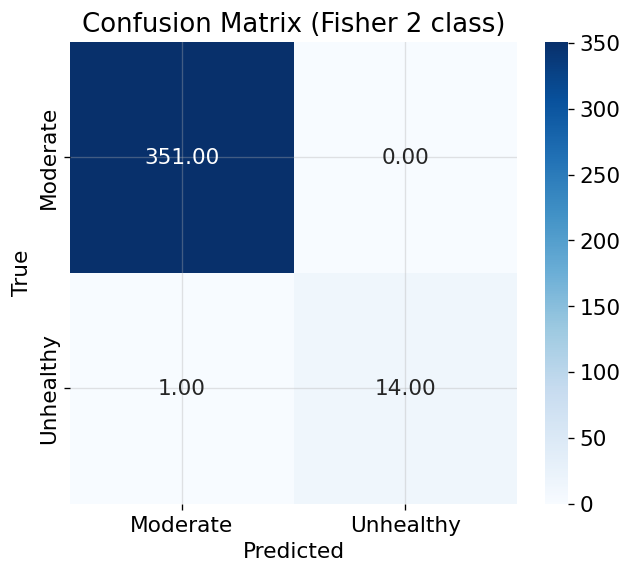



===== 3 Class Confusion Matrix =====


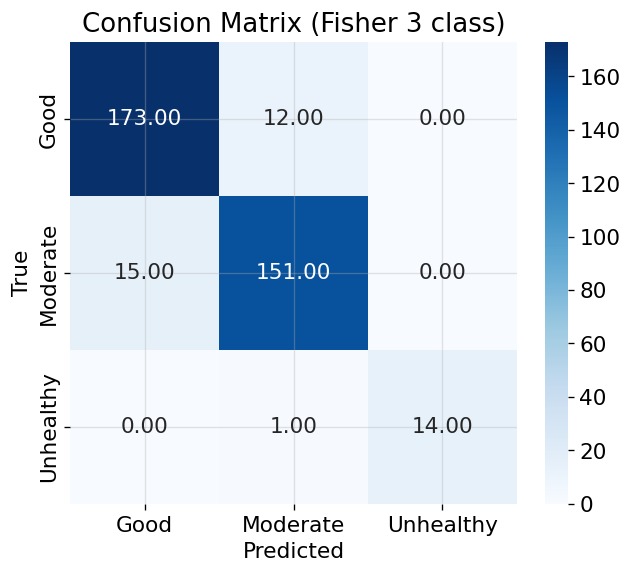

In [9]:
# 2 class
print("===== 2 Class Confusion Matrix =====")
conf_mat1 = confusion_matrix(y_test1, y_pred1)

plt.figure(figsize=(6,5))
sns.heatmap(conf_mat1, 
            annot=True, 
            fmt='.2f', 
            xticklabels=labelling1.classes_, 
            yticklabels=labelling1.classes_, 
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Fisher 2 class)")
plt.show()

# 3 class
print("\n\n===== 3 Class Confusion Matrix =====")
conf_mat2 = confusion_matrix(y_test2, y_pred2)

plt.figure(figsize=(6,5))
sns.heatmap(conf_mat2, 
            annot=True, 
            fmt='.2f', 
            xticklabels=labelling2.classes_, 
            yticklabels=labelling2.classes_, 
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Fisher 3 class)")
plt.show()

## LDA Projection

===== 2 Class Projection (Vertical) =====


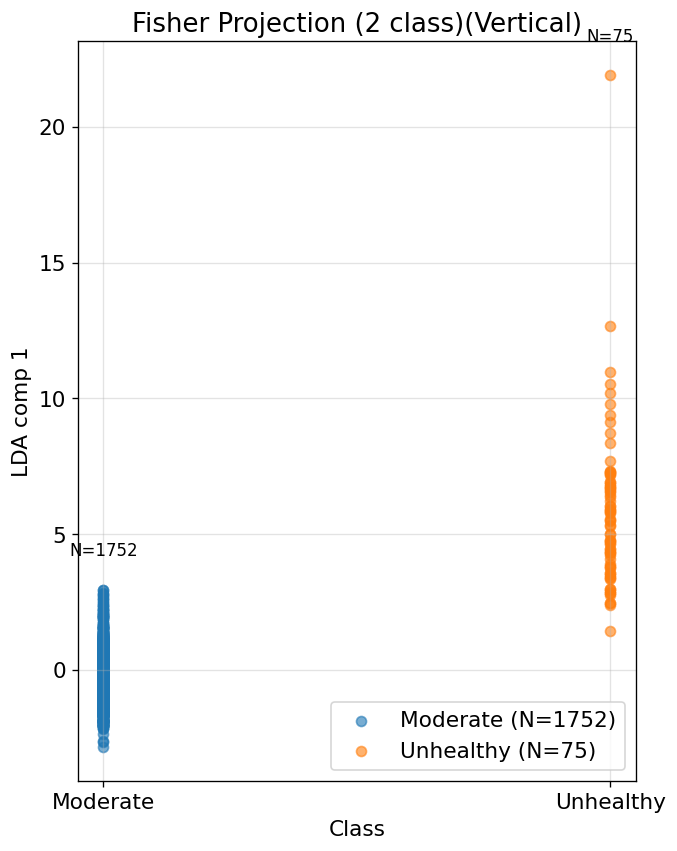



===== 3 Class Projection =====


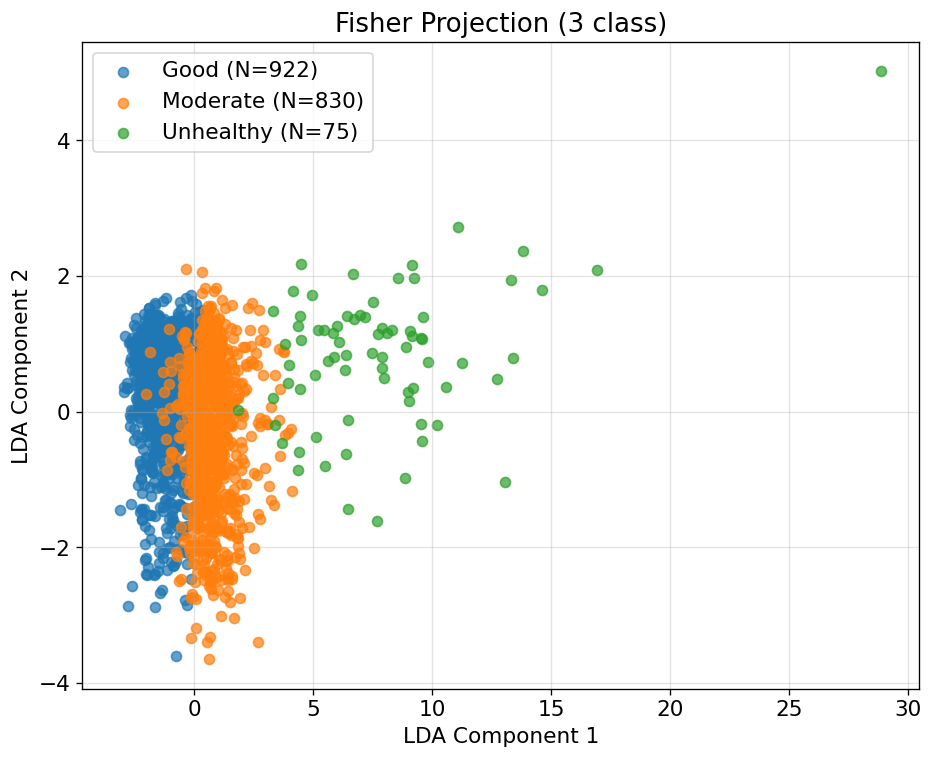

In [10]:
# 2 class projection
def plot_lda_projection(X_lda, y, classes, title="LDA Projection",vertical=False):
    plt.figure(figsize=(6,8) if vertical else (8,6))
    for i, cls in enumerate(classes):
        if vertical:
            pos = np.full(sum(y==i), i)
            plt.scatter(pos, X_lda[y==i,0], alpha=0.6, label=f"{cls} (N={sum(y==i)})")
            plt.text(i, X_lda[y==i,0].max() + 0.05*np.ptp(X_lda[:,0]), f'N={sum(y==i)}',
                     ha='center', fontsize=10, color='black')
        else:
            pos = np.full(sum(y==i), i)
            plt.scatter(X_lda[y==i,0], pos, alpha=0.6, label=f"{cls} (N={sum(y==i)})")
            plt.text(X_lda[y==i,0].max() + 0.05*np.ptp(X_lda[:,0]), i, f'N={sum(y==i)}',
                     va='center', fontsize=10, color='black')

    plt.xlabel('LDA comp 1' if not vertical else 'Class')
    plt.ylabel('Class' if not vertical else 'LDA comp 1')
    if vertical:
        plt.xticks(range(len(classes)), classes)
    else:
        plt.yticks(range(len(classes)), classes)
    plt.title(title)
    plt.legend(loc='lower right')
    plt.show()

# Call plot_lda_projection function to plot horizontal & vertical plot projection (2 class)
print("===== 2 Class Projection (Vertical) =====")
X_lda1 = lda1.transform(X1)
# plot_lda_projection(X_lda1, y_encoding1, labelling1.classes_, title="Fisher Projection (2 class)(Horizontal)", vertical=False)
plot_lda_projection(X_lda1, y_encoding1, labelling1.classes_, title="Fisher Projection (2 class)(Vertical)", vertical=True)

# Plot 3 class projection
print("\n\n===== 3 Class Projection =====")
X_lda2 = lda2.transform(X2)
n_comp = X_lda2.shape[1]
plt.figure(figsize=(9,7))
for i, cls in enumerate(labelling2.classes_):
    plt.scatter(X_lda2[y_encoding2 == i, 0], X_lda2[y_encoding2 == i, 1],
                alpha=0.7, label=f"{cls} (N={sum(y_encoding2==i)})")
plt.xlabel("LDA Component 1")
plt.ylabel("LDA Component 2")
plt.title("Fisher Projection (3 class)")
plt.legend()
plt.show()

## Feature Importance

In [11]:
# 2 class
coef1 = np.mean(np.abs(lda1.coef_), axis=0)
feat_imp1 = pd.Series(coef1, index=features).sort_values(ascending=False)
print("Feature importances (2 class): ")
print(feat_imp1)

# 3 class
coef2 = np.mean(np.abs(lda2.coef_), axis=0)
feat_imp2 = pd.Series(coef2, index=features).sort_values(ascending=False)
print("\nFeature importances (3 class): ")
print(feat_imp2)

Feature importances (2 class): 
PM25     152.756669
Ozone     16.401957
CO        12.284928
NO2       11.545818
PM10       1.624525
dtype: float64

Feature importances (3 class): 
PM25     108.518834
Ozone     12.817955
CO         8.001803
NO2        3.101633
PM10       1.134464
dtype: float64
